# TODO 2 — Induire la métadonnée dans une nouvelle observable

La 2PCF classique ne « voit » que les positions. On construit ici deux observables
qui incorporent la métadonnée (population), pour comparer données et modèles sur le
couplage position ↔ population :

1. **Profil de population cumulée M(r)** — pour chaque point, la population cumulée
   dans un cercle de rayon r (somme des métadonnées des points inclus), en fonction
   de r. La pente log-log de ⟨M(r)⟩ est une « **dimension massique** » D_M,
   l'analogue pondéré-par-la-population de la dimension de corrélation D₂.
2. **La « 2PCF des gens »** — on superpose à chaque point un nombre de nœuds
   proportionnel à sa métadonnée, puis on mesure la 2PCF du nuage étendu : c'est la
   2PCF *des habitants* et non des villes. Implémentée de deux façons équivalentes :
   superposition littérale, et estimateur de Landy-Szalay **pondéré par les
   marques** (sans le coût N² du nuage étendu).

Code : [`src/metadata_marks.py`](../src/metadata_marks.py).

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

ROOT = Path.cwd().resolve().parent           # racine fake_world_paper_july_2026/
sys.path.insert(0, str(ROOT / "src"))
import synthese_utils as su
import metadata_marks as mm

# Palette fixe (Okabe-Ito, sûre pour le daltonisme) — chaque entité garde la
# même couleur dans tous les notebooks du projet. Les deux variantes
# d'attribution de population (a) et (b) ont chacune leur teinte.
C = {"data": "#000000", "sp": "#0072B2", "rk": "#56B4E9", "split": "#CC79A7",
     "null": "#999999", "level": "#E69F00", "poisson": "#009E73"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})

DATASET_NAME = "Belgium Cities"   # petit (N=815) et porteur d'une vraie population
ds = su.DATASETS[DATASET_NAME]
ld = su.load_dataset(ds)
xy_data, pop_data, geom = ld["xy_norm"], ld["pop_data"], ld["geom_norm"]
print(f"{DATASET_NAME} : N={ld['N_real']}, population min/med/max = "
      f"{pop_data.min():.0f}/{np.median(pop_data):.0f}/{pop_data.max():.0f}")

# Modèle : SP mixte + densité locale (même pipeline que le notebook 01).
# Les DEUX variantes d'attribution de population y sont propagées :
#   (a) loi de puissance pop ∝ rho^beta, beta calibré sur l'exposant de Zipf
#   (b) rank-matching : les vraies populations appariées par rang de densité
xy_sp, is_sp = su.build_sp_mixture(ds, ld["gdf_edge"], ld["bounds"], geom,
                                   ld["r_data"], ld["xi_data"],
                                   N_target=ld["N_real"], seed=su.SEED,
                                   return_labels=True)
rho = mm.local_density_knn(xy_sp, k=10)
beta_star, _ = mm.calibrate_beta_on_zipf(rho, su.fit_zipf_exponent(pop_data),
                                         pop_data.sum())
pop_sp = mm.pop_powerlaw(rho, beta_star, pop_data.sum())      # variante (a)
pop_sp_rk = mm.pop_rank_matching(rho, pop_data)               # variante (b)
# variante (c) : split SP/fond — les |SP| plus grandes pop sur les noeuds
# fractals, le reste sur le fond, au hasard dans chaque groupe (cf notebook 01)
pop_sp_c = mm.pop_split_sp_background(is_sp, pop_data, seed=0)

# Nulls : marques mélangées sur les points des données ; Poisson + marques données
rng = np.random.default_rng(0)
pop_shuf = rng.permutation(pop_data)
xy_pois = su.simulate_poisson(len(xy_data), geom, seed=1)
print(f"SP mixte : N={len(xy_sp)}, beta*={beta_star:.2f}")
print(f"Zipf — données {su.fit_zipf_exponent(pop_data):.2f} | "
      f"(a) {su.fit_zipf_exponent(pop_sp):.2f} | "
      f"(b) {su.fit_zipf_exponent(pop_sp_rk):.2f} | "
      f"(c) {su.fit_zipf_exponent(pop_sp_c):.2f}")
print(f"(c) : {is_sp.sum()} noeuds SP / {len(is_sp)} "
      f"({100*is_sp.sum()/len(is_sp):.0f} %)")

  N=815  échelle=272.8 km


  gamma_data=0.515  r0_norm=0.00390
Belgium Cities : N=815, population min/med/max = 19/8277/1235192


SP mixte : N=815, beta*=1.50
Zipf — données 1.23 | (a) 1.32 | (b) 1.23 | (c) 1.23
(c) : 190 noeuds SP / 815 (23 %)


## Observable 1 — profil de population cumulée M(r)

M_i(r) = Σ_{j : d_ij ≤ r} pop_j pour chaque point i ; on trace la moyenne sur i.
Toutes les variantes portent la **même population totale**, donc toutes les courbes
convergent vers Σpop aux grands r : l'information est dans la *forme* aux petits et
moyens r.

**⚠️ La pente D_M ne mesure pas le couplage.** On pourrait croire que la « dimension
massique » D_M (pente log-log de M(r)) détecte si les fortes populations s'agrègent.
Elle ne le fait pas. En décomposant :

$$\langle M(r)\rangle \;=\; \underbrace{\langle \mathrm{pop}\rangle \cdot \langle N(r)\rangle}_{\text{géométrie des points}} \;+\; \underbrace{\mathrm{Cov}\big(\mathrm{pop}_j,\, n_j(r)\big)}_{\text{couplage}}$$

où n_j(r) est le **nombre de voisins du nœud j dans un rayon r** (et ⟨N(r)⟩ = ⟨n(r)⟩
sa moyenne). L'identité s'obtient en intervertissant les deux sommes : au lieu de
demander « quelle population autour de i ? », on demande « combien de nœuds i comptent
j dans leur voisinage ? ». Le premier terme ne dépend **que des positions** et domine
la pente ; le couplage n'entre que par la covariance, qui agit comme une correction
quasi *multiplicative* — elle décale la courbe verticalement sans changer sa pente.
Vérification numérique sur la Belgique :

| | D_M |
|---|---|
| Données | 2.31 |
| Null (marques mélangées, 30 tirages) | 2.26 ± 0.13 → **écart 0.4σ, non significatif** |
| Poisson (positions changées, marques réelles) | 2.18 |

⇒ **D_M ne distingue pas les données de leur null** : il ne valide pas le couplage.
On le garde comme descripteur géométrique, rien de plus.

> **Escalier, pas interpolation.** M_i(r) est une fonction *en escalier* (elle saute à
> chaque voisin franchi). Le code l'évalue exactement par recherche dichotomique.
> Interpoler linéairement entre voisins — l'idiome naturel mais faux — anticiperait la
> population du voisin suivant, surestimerait M(r) jusqu'à ~30 % aux petits r et
> casserait l'identité ci-dessus (qui n'y tenait qu'à 30 % près, contre 0.000 % ici).

**L'observable qui, elle, discrimine :** on normalise par le profil de comptage, ce
qui élimine exactement le terme de géométrie :

$$M_{\mathrm{norm}}(r) \;=\; \frac{\langle M(r)\rangle}{\langle \mathrm{pop}\rangle \cdot \langle N(r)\rangle}$$

- **= 1** : la population dans un rayon r est celle attendue vu le nombre de voisins
  → aucun couplage. C'est la valeur du null, *par construction*.
- **> 1** : les nœuds sont entourés de plus de population qu'attendu à l'échelle r
  → les fortes populations se regroupent.

C'est le second panneau de la figure ci-dessous, avec le null (± σ sur 30
permutations) en bande grise : il est plat à 1.01, et les données culminent à ≈ 1.74
vers r ≈ 0.005 (≈ 1.5 km) — un nœud réel porte ~74 % de population de plus dans son
voisinage qu'un nœud aux marques mélangées.

### Pourquoi normaliser, plutôt que de tracer la covariance seule ?

Question légitime : puisque Cov(pop_j, n_j(r)) *est* le terme de couplage, pourquoi ne
pas s'arrêter là ? De fait, **M_norm − 1 n'est que la covariance rééchelonnée** :

$$M_{\mathrm{norm}}(r) - 1 \;=\; \frac{\mathrm{Cov}\big(\mathrm{pop}_j,\, n_j(r)\big)}{\langle \mathrm{pop}\rangle \cdot \langle N(r)\rangle}$$

Les deux portent donc **la même information**. La division n'isole rien de plus ; elle
sert à trois choses, et elle a un coût. Le 3ᵉ panneau de la figure trace la covariance
brute pour rendre l'arbitrage visible.

**Ce que la normalisation apporte**
1. **Une grandeur sans dimension.** Cov s'exprime en « habitants × voisins » : compter
   les populations en milliers la diviserait par 1000 sans que rien de physique ne change.
2. **La comparabilité entre systèmes** — l'argument décisif. Le pic de covariance vaut
   840 561 en Belgique contre 100 387 en Autriche, soit 8.4× ; mais la population moyenne
   d'une ville y est de 15.7 k contre 4.0 k, donc **3.9× de cet écart ne sont que la
   taille moyenne des villes**, un artefact du découpage administratif. M_norm (1.74 vs
   1.16) ne souffre pas de ce biais.
3. **La convention du domaine.** ξ(r) = DD/RR − 1 et k_mm(r) = ⟨m_i m_j⟩/⟨m⟩² sont
   construites exactement pareil : observé / attendu. M_norm est « le ξ de la famille
   M(r) ».

**Ce qu'elle coûte** — visible sur la figure : aux petits r, ⟨N(r)⟩ → 0, donc M_norm
divise 0 par 0 et le bruit explose (Belgique à 0.7 km : M_norm = 0.79 pour une covariance
de −89, une valeur négligeable). La covariance, elle, tend proprement vers 0 aux deux
bouts — à petit r car n_j = 0 partout, à grand r car n_j = N−1 partout.

⇒ **M_norm pour comparer et publier, covariance brute pour lire les petites échelles.**

variante                          D_M   M_norm(pic)
Données                          2.31   1.74 à r=0.0055
SP + densité locale (a)          1.42   3.30 à r=0.0153
SP + rank-matching (b)           1.46   3.13 à r=0.0119
SP + split SP/fond (c)           1.40   2.35 à r=0.0055
Données, marques mélangées       2.28   1.10 à r=0.0033
Poisson + marques données        2.18   1.22 à r=0.0119

D_M  : données 2.310 vs null 2.260 ± 0.132  → écart 0.4 sigma (non significatif)
M_norm : null plat à 1.01 — l'écart des données à 1 EST le couplage


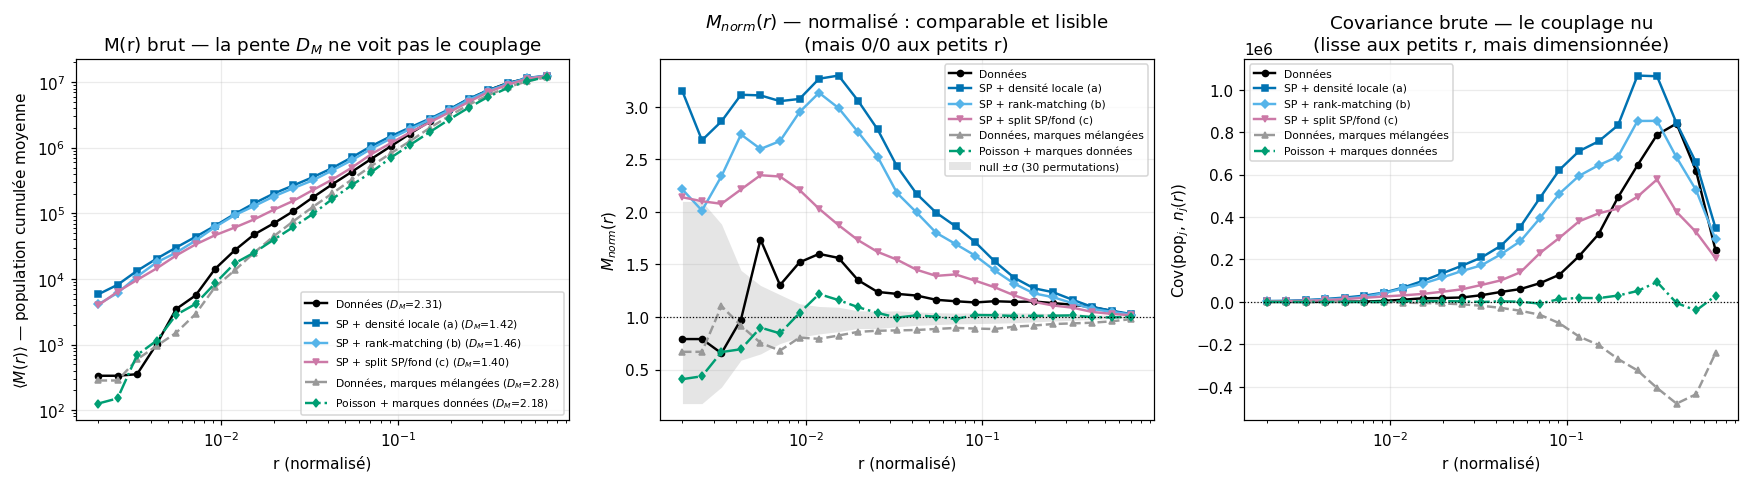

In [2]:
r_grid = np.logspace(np.log10(2e-3), np.log10(0.7), 24)
variants = {
    "Données":                       (xy_data, pop_data,  C["data"],    "o-"),
    "SP + densité locale (a)":       (xy_sp,   pop_sp,    C["sp"],      "s-"),
    "SP + rank-matching (b)":        (xy_sp,   pop_sp_rk, C["rk"],      "D-"),
    "SP + split SP/fond (c)":        (xy_sp,   pop_sp_c,  C["split"],   "v-"),
    "Données, marques mélangées":    (xy_data, pop_shuf,  C["null"],    "^--"),
    "Poisson + marques données":     (xy_pois, pop_data,  C["poisson"], "d-."),
}
profiles, norms, COV, DM = {}, {}, {}, {}
for k, (xy, p, *_ ) in variants.items():
    M_norm, M, N = mm.normalized_population_profile(xy, p, r_grid)
    profiles[k], norms[k] = M, M_norm
    COV[k] = mm.covariance_profile(M, N, p)      # couplage brut, non normalisé
    DM[k] = mm.mass_dimension(r_grid, M, a=1, b=16)

# Null moyenné : M_norm attendu plat à 1 (et D_M de référence pour tester D_M)
null_m, null_s, dm_null, dm_null_s = mm.shuffled_null_profile(
    xy_data, pop_data, r_grid, n_shuffle=30, seed=0)

print(f"{'variante':30s} {'D_M':>6s}   M_norm(pic)")
for k in variants:
    i_pk = np.nanargmax(norms[k][1:16]) + 1
    print(f"{k:30s} {DM[k]:6.2f}   {norms[k][i_pk]:.2f} à r={r_grid[i_pk]:.4f}")
print(f"\nD_M  : données {DM['Données']:.3f} vs null {dm_null:.3f} ± {dm_null_s:.3f}"
      f"  → écart {abs(DM['Données']-dm_null)/dm_null_s:.1f} sigma (non significatif)")
print(f"M_norm : null plat à {np.nanmean(null_m):.2f} — l'écart des données à 1 EST le couplage")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for k, (xy, p, c, st) in variants.items():
    axes[0].loglog(r_grid, profiles[k], st, ms=4, c=c, lw=1.6,
                   label=f"{k} ($D_M$={DM[k]:.2f})")
    axes[1].semilogx(r_grid, norms[k], st, ms=4, c=c, lw=1.6, label=k)
    axes[2].semilogx(r_grid, COV[k], st, ms=4, c=c, lw=1.6, label=k)
axes[0].set_xlabel("r (normalisé)")
axes[0].set_ylabel("$\\langle M(r) \\rangle$ — population cumulée moyenne")
axes[0].set_title("M(r) brut — la pente $D_M$ ne voit pas le couplage")
axes[0].legend(fontsize=7)

axes[1].fill_between(r_grid, null_m - null_s, null_m + null_s, color=C["null"],
                     alpha=0.25, lw=0, label="null ±σ (30 permutations)")
axes[1].axhline(1, c="k", lw=0.8, ls=":")
axes[1].set_xlabel("r (normalisé)")
axes[1].set_ylabel("$M_{norm}(r)$")
axes[1].set_title("$M_{norm}(r)$ — normalisé : comparable et lisible\n(mais 0/0 aux petits r)")
axes[1].legend(fontsize=7)

axes[2].axhline(0, c="k", lw=0.8, ls=":")
axes[2].set_xlabel("r (normalisé)")
axes[2].set_ylabel("$\\mathrm{Cov}(\\mathrm{pop}_j,\\, n_j(r))$")
axes[2].set_title("Covariance brute — le couplage nu\n(lisse aux petits r, mais dimensionnée)")
axes[2].legend(fontsize=7)
fig.tight_layout(); plt.show()

## Observable 2 — la « 2PCF des gens »

**Principe** : on superpose à chaque point un nombre de nœuds n_i ∝ pop_i, puis on
mesure la 2PCF du nuage étendu. Chaque paire de points (i, j) compte alors
n_i·n_j fois : c'est exactement l'estimateur de Landy-Szalay **pondéré par les
marques** (DD pondéré par w_i·w_j, DR par w_i, RR inchangé), qui évite le coût
quadratique du nuage étendu.

On valide d'abord l'équivalence des deux implémentations sur les données.

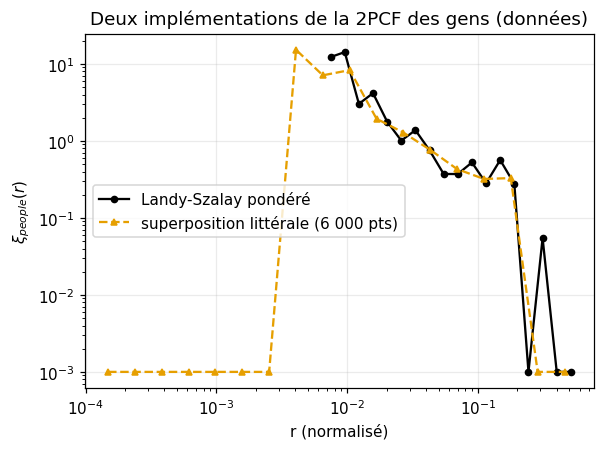

In [3]:
# Validation : estimateur pondéré ≡ superposition littérale (n_i ∝ pop_i)
r_w, xi_w = mm.compute_2pcf_people(xy_data, pop_data, geom)
xy_sup = mm.superpose_people(xy_data, pop_data, n_total=6000, seed=2)
r_sup, xi_sup = su.compute_2pcf_norm(xy_sup, geom)

fig, ax = plt.subplots(figsize=(5.6, 4.2))
ax.loglog(r_w, np.clip(xi_w, 1e-3, None), "o-", ms=4, c=C["data"],
          label="Landy-Szalay pondéré")
ax.loglog(r_sup, np.clip(xi_sup, 1e-3, None), "^--", ms=4, c=C["level"],
          label="superposition littérale (6 000 pts)")
ax.set_xlabel("r (normalisé)"); ax.set_ylabel("$\\xi_{people}(r)$")
ax.set_title("Deux implémentations de la 2PCF des gens (données)")
ax.legend(); fig.tight_layout(); plt.show()

### Comparaison données / modèle / null

- la 2PCF **des nœuds** (non pondérée) sert de référence : l'écart entre
  ξ_people et ξ_nœuds mesure ce que la métadonnée ajoute ;
- le null « marques mélangées » doit redonner ξ_people ≈ ξ_nœuds ;
- si la densité locale induit le bon couplage, le SP marqué doit suivre le
  raidissement observé dans les données.

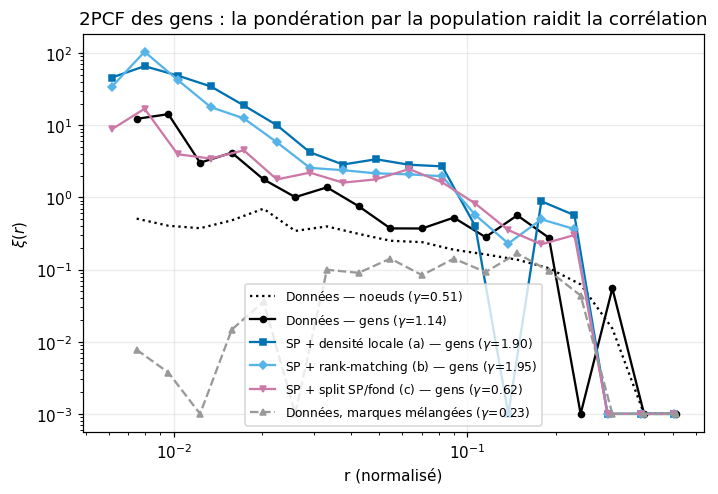

gamma_people (c), 10 tirages : 0.666 ± 0.134   (la courbe tracée = tirage seed 0)


In [4]:
res_people = {
    "Données — gens": mm.compute_2pcf_people(xy_data, pop_data, geom),
    "SP + densité locale (a) — gens": mm.compute_2pcf_people(xy_sp, pop_sp, geom),
    "SP + rank-matching (b) — gens": mm.compute_2pcf_people(xy_sp, pop_sp_rk, geom),
    "SP + split SP/fond (c) — gens": mm.compute_2pcf_people(xy_sp, pop_sp_c, geom),
    "Données, marques mélangées": mm.compute_2pcf_people(xy_data, pop_shuf, geom),
}
styles = {"Données — gens": ("o-", C["data"]),
          "SP + densité locale (a) — gens": ("s-", C["sp"]),
          "SP + rank-matching (b) — gens": ("D-", C["rk"]),
          "SP + split SP/fond (c) — gens": ("v-", C["split"]),
          "Données, marques mélangées": ("^--", C["null"])}

fig, ax = plt.subplots(figsize=(6.6, 4.6))
ax.loglog(ld["r_data"], np.clip(ld["xi_data"], 1e-3, None), ":", c=C["data"],
          lw=1.5, label=f"Données — noeuds ($\\gamma$={ld['gamma_fit']:.2f})")
gammas = {}
for k, (r, xi) in res_people.items():
    g, _ = su.fit_powerlaw_norm(r, xi)
    gammas[k] = g
    st, c = styles[k]
    lbl = f"{k} ($\\gamma$={g:.2f})" if g is not None else k
    ax.loglog(r, np.clip(xi, 1e-3, None), st, ms=4, c=c, label=lbl)
ax.set_xlabel("r (normalisé)"); ax.set_ylabel("$\\xi(r)$")
ax.set_title("2PCF des gens : la pondération par la population raidit la corrélation")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

# (c) est stochastique intra-groupe : gamma_people moyen ± std sur 10 tirages
g_c_draws = []
for s_ in range(10):
    r_c, xi_c = mm.compute_2pcf_people(
        xy_sp, mm.pop_split_sp_background(is_sp, pop_data, seed=s_), geom)
    g_c_, _ = su.fit_powerlaw_norm(r_c, xi_c)
    if g_c_ is not None:
        g_c_draws.append(g_c_)
print(f"gamma_people (c), 10 tirages : {np.mean(g_c_draws):.3f} ± {np.std(g_c_draws):.3f}"
      f"   (la courbe tracée = tirage seed 0)")

In [5]:
import pandas as pd

rows = [dict(observable="D_M (dimension massique) [non discriminant]", variante=k,
             valeur=round(v, 3)) for k, v in DM.items()]
# M_norm au pic : c'est LUI qui mesure le couplage (1 = aucun couplage)
for k in variants:
    i_pk = int(np.nanargmax(norms[k][1:16]) + 1)
    rows.append(dict(observable="M_norm (pic, 1=aucun couplage)", variante=k,
                     valeur=round(float(norms[k][i_pk]), 3)))
rows += [dict(observable="gamma_people", variante=k,
              valeur=(round(g, 3) if g is not None else None))
         for k, g in gammas.items()]
rows += [dict(observable="gamma_noeuds", variante="Données",
              valeur=round(ld["gamma_fit"], 3))]
df = pd.DataFrame(rows)
out_csv = ROOT / "out" / "02_metadata_observables_summary.csv"
df.to_csv(out_csv, index=False)
print(df.to_string(index=False))
print("->", out_csv)

                                 observable                       variante  valeur
D_M (dimension massique) [non discriminant]                        Données   2.310
D_M (dimension massique) [non discriminant]        SP + densité locale (a)   1.423
D_M (dimension massique) [non discriminant]         SP + rank-matching (b)   1.458
D_M (dimension massique) [non discriminant]         SP + split SP/fond (c)   1.403
D_M (dimension massique) [non discriminant]     Données, marques mélangées   2.276
D_M (dimension massique) [non discriminant]      Poisson + marques données   2.179
             M_norm (pic, 1=aucun couplage)                        Données   1.738
             M_norm (pic, 1=aucun couplage)        SP + densité locale (a)   3.298
             M_norm (pic, 1=aucun couplage)         SP + rank-matching (b)   3.134
             M_norm (pic, 1=aucun couplage)         SP + split SP/fond (c)   2.349
             M_norm (pic, 1=aucun couplage)     Données, marques mélangées   1.104
    

## Lecture des résultats

Rappel : les deux variantes d'attribution de population sont tracées partout —
**(a) densité locale** (pop ∝ ρ^β, β calibré sur Zipf : le modèle génère ses propres
populations) et **(b) rank-matching** (vraies populations appariées par rang de
densité : distribution exacte, seul le placement est modélisé). Un écart entre (a) et
(b) pointe la *forme* de la distribution ; un écart de (b) aux données pointe le
*placement*.

- **M(r) brut et D_M** : ⚠️ **D_M ne valide pas le couplage** — données 2.31 contre un
  null à 2.26 ± 0.13, soit 0.4σ : indiscernable. C'est un descripteur de la géométrie
  des *points*, à lire comme tel. (Une version antérieure de ce notebook affirmait que
  D_M des données devait être *plus faible* que celle des nulls ; la mesure la
  contredit — il est même légèrement plus grand, et l'écart n'est pas significatif.)
- **M_norm(r)** : l'observable qui discrimine. Le null est plat à 1.01 (comme le
  prédit la décomposition), et les données culminent à ≈ 1.74 vers r ≈ 1.5 km : un nœud
  réel a ~74 % de population de plus dans son voisinage que si les marques étaient
  mélangées. Comparer le SP (a)/(b) aux données sur *cette* courbe.
- **Le SP sur-couple** : 3.30 en (a) et 3.13 en (b), contre 1.74 pour les données —
  environ 2× trop. Cohérent avec Δγ (+0.15 vs +0.07) et γ_people (1.90 vs 1.14) : les
  trois observables concordent, le couplage est du bon signe mais trop fort. Cause
  identifiée : le modèle fait de la population une fonction *déterministe* de la
  densité (Spearman = 1), alors que dans les données pop et densité locale sont
  quasi *décorrélées* en rang (Spearman ≈ −0.02 à k=10). La prémisse « les grandes
  villes sont là où c'est dense » est bien plus faible que ce que le modèle impose.
- **Variante (c), split SP/fond** (courbes roses) : sans lien local densité→taille,
  le couplage s'effondre — ξ_people sous-couple (γ ≈ 0.67 ± 0.13 sur 10 tirages,
  contre 1.14 pour les données) et M_norm reste bien plus bas que (a)/(b). La
  hiérarchie « nœud structuré vs fond » ne suffit pas.
- **2PCF des gens** : γ_people ≫ γ_nœuds dans les données (les *habitants* sont
  beaucoup plus corrélés que les *villes*) ; le null redonne ξ_nœuds. La capacité
  du SP + densité locale à reproduire ce raidissement est le test le plus exigeant du
  couplage induit.
- **Candidates pour le papier** : M_norm(r) et ξ_people (section « Characterizing
  spatial distribution in function of node metadata », cf. `paper/draft.tex`,
  section rouge *New results — July 2026*). D_M n'y a pas sa place comme mesure de
  couplage.

**Suites** : balayer les 9 datasets, ajouter M_norm(r) et ξ_people dans
`scripts/compute_all.py` (cache), et confronter le SP marqué au Hawkes marqué
(`su.simulate_marked_hawkes`) sur ces deux observables.